# SMS spam classification: TF-IDF baselines vs. BERT embeddings

Compares classical TF-IDF models with classifiers trained on fixed BERT embeddings, using one
deduplicated train/validation/test split. Models are chosen on the validation set and reported on the test set.

**Setup:** `pip install -r requirements.txt` on Linux or WSL. `tensorflow-text` has no Windows build.
On CPU, embedding takes several minutes.

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_hub as hub
import tensorflow_text  # noqa: F401 - registers the ops the BERT preprocessor needs
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

SEED = 42
THRESHOLD = 0.5
ARTIFACT_DIR = Path("artifacts")
DATA_FILE = "SPAM text message 20170820 - Data.csv"
DATA_URL = (
    "https://raw.githubusercontent.com/ElsieElsevier/llm-spam-text-biclassification/"
    "main/SPAM%20text%20message%2020170820%20-%20Data.csv"
)

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print("GPUs:", tf.config.list_physical_devices("GPU") or "none, running on CPU")

GPUs: none, running on CPU


## Data

The CSV has 415 repeated messages. They are removed **before** splitting so that no test message also
appears in training. The split is stratified 70/15/15.

In [2]:
def load_data():
    """Read the CSV from the repo, or download it if the notebook is running elsewhere."""
    return pd.read_csv(DATA_FILE if Path(DATA_FILE).exists() else DATA_URL)


def prepare_data(df):
    """Deduplicate, encode labels (spam=1, ham=0) and split into train/val/test."""
    unique = df.drop_duplicates("Message")
    texts = unique["Message"].tolist()
    labels = unique["Category"].map({"spam": 1, "ham": 0}).astype(int).to_numpy()

    X_train, X_temp, y_train, y_temp = train_test_split(
        texts, labels, test_size=0.3, random_state=SEED, stratify=labels
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp
    )
    assert not set(X_train) & set(X_test), "test messages leaked into training"
    return {
        "train": (X_train, y_train),
        "val": (X_val, y_val),
        "test": (X_test, y_test),
    }


df = load_data()
splits = prepare_data(df)
print(f"Raw rows: {len(df)}; unique messages: {df['Message'].nunique()}")
for name, (texts, labels) in splits.items():
    print(f"{name:>5}: {len(texts)} messages, {labels.sum()} spam ({labels.mean():.1%})")

Raw rows: 5572; unique messages: 5157
train: 3609 messages, 449 spam (12.4%)
  val: 774 messages, 96 spam (12.4%)
 test: 774 messages, 96 spam (12.4%)


## TF-IDF baselines

Adapted from Jeremiah Fowler's preprocessing notebook. The vectorizer sits inside a pipeline, so it only
learns from the training set. The logistic regression's `C` is chosen on the validation set.

In [3]:
def tfidf_vectorizer():
    return TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)


def train_tfidf_models(splits):
    X_train, y_train = splits["train"]
    X_val, y_val = splits["val"]

    naive_bayes = make_pipeline(tfidf_vectorizer(), MultinomialNB()).fit(X_train, y_train)

    best_logreg, best_f1 = None, -1.0
    for C in (1, 10, 100):
        candidate = make_pipeline(
            tfidf_vectorizer(),
            LogisticRegression(C=C, max_iter=2000, class_weight="balanced"),
        ).fit(X_train, y_train)
        val_f1 = f1_score(y_val, candidate.predict(X_val))
        print(f"C={C}: validation F1 = {val_f1:.4f}")
        if val_f1 > best_f1:
            best_logreg, best_f1 = candidate, val_f1

    return {"tfidf_naive_bayes": naive_bayes, "tfidf_logreg": best_logreg}


models = train_tfidf_models(splits)

C=1: validation F1 = 0.8912


C=10: validation F1 = 0.9053


C=100: validation F1 = 0.9158


## BERT embeddings

BERT's weights stay frozen. Each message becomes a 768-dimension `pooled_output` vector, which is derived
from the `[CLS]` token. No stop-word removal or other cleaning is applied, because BERT is designed to read
full sentences.

In [4]:
class BertEmbedding:
    def __init__(self):
        self.preprocessor = hub.KerasLayer("https://tfhub.dev/tensorflow/bert_en_uncased_preprocess/3")
        self.encoder = hub.KerasLayer(
            "https://tfhub.dev/tensorflow/bert_en_uncased_L-12_H-768_A-12/4", trainable=False
        )

    def get_embeddings(self, texts, batch_size=32):
        dataset = tf.data.Dataset.from_tensor_slices(tf.constant(list(texts))).batch(batch_size)
        batches = [
            self.encoder(self.preprocessor(batch))["pooled_output"].numpy() for batch in dataset
        ]
        return np.vstack(batches)


bert = BertEmbedding()
embeddings = {name: bert.get_embeddings(texts) for name, (texts, _) in splits.items()}
{name: values.shape for name, values in embeddings.items()}

{'train': (3609, 768), 'val': (774, 768), 'test': (774, 768)}

## Classifiers on the embeddings

Two classifiers use the same embeddings: the project's small neural network and a plain logistic regression.

Neural network stopped after 300 epochs


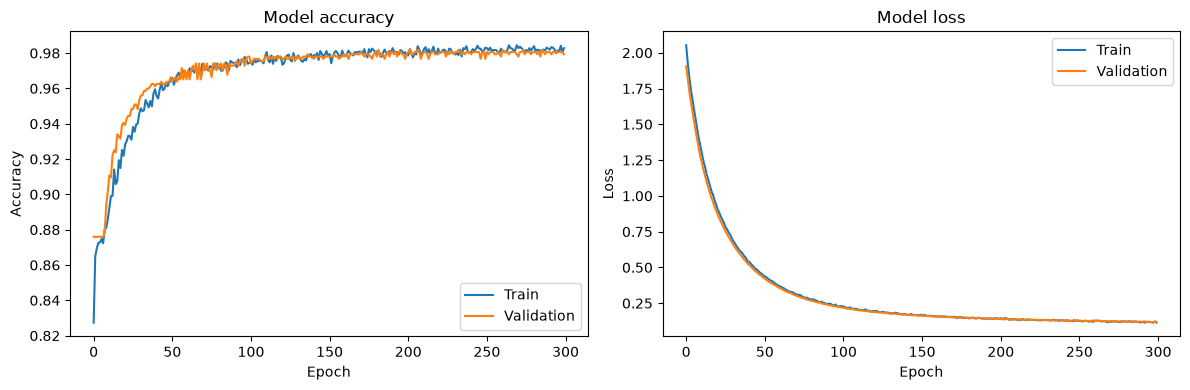

In [5]:
def create_mlp(input_dim, learning_rate=0.0001, dropout_rates=(0.5, 0.4)):
    model = Sequential([
        tf.keras.Input(shape=(input_dim,)),
        Dense(64, activation="relu", kernel_regularizer=l2(0.01)),
        Dropout(dropout_rates[0]),
        Dense(32, activation="relu", kernel_regularizer=l2(0.01)),
        Dropout(dropout_rates[1]),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss="binary_crossentropy", metrics=["accuracy"])
    return model


def train_mlp(embeddings, splits, batch_size=128, epochs=300, patience=10):
    model = create_mlp(embeddings["train"].shape[1])
    early_stopping = EarlyStopping(
        monitor="val_loss", patience=patience, min_delta=0.001, restore_best_weights=True
    )
    history = model.fit(
        embeddings["train"],
        splits["train"][1],
        validation_data=(embeddings["val"], splits["val"][1]),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stopping],
        verbose=0,
    )
    return model, history


def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    for position, (metric, title) in enumerate([("accuracy", "Accuracy"), ("loss", "Loss")], start=1):
        plt.subplot(1, 2, position)
        plt.plot(history.history[metric], label="Train")
        plt.plot(history.history[f"val_{metric}"], label="Validation")
        plt.title(f"Model {title.lower()}")
        plt.xlabel("Epoch")
        plt.ylabel(title)
        plt.legend()
    plt.tight_layout()
    plt.show()


models["bert_mlp"], history = train_mlp(embeddings, splits)
models["bert_logreg"] = LogisticRegression(max_iter=5000).fit(embeddings["train"], splits["train"][1])
print(f"Neural network stopped after {len(history.history['loss'])} epochs")
plot_training_history(history)

## Evaluation

The best model is picked by validation F1. The test columns are not used for any choice in this notebook.
Spam is the positive class, so a false positive is a legitimate message flagged as spam.

In [6]:
TEXT_MODELS = {"tfidf_naive_bayes", "tfidf_logreg"}


def scores_from_inputs(model, inputs):
    if isinstance(model, tf.keras.Model):
        return model.predict(inputs, verbose=0).ravel()
    return model.predict_proba(inputs)[:, 1]


def evaluate(split):
    rows = {}
    for name, model in models.items():
        inputs = splits[split][0] if name in TEXT_MODELS else embeddings[split]
        predictions = scores_from_inputs(model, inputs) > THRESHOLD
        tn, fp, fn, tp = confusion_matrix(splits[split][1], predictions).ravel()
        precision, recall = tp / (tp + fp), tp / (tp + fn)
        rows[name] = {
            "accuracy": (tp + tn) / (tp + tn + fp + fn),
            "precision": precision,
            "recall": recall,
            "f1": 2 * precision * recall / (precision + recall),
            "specificity": tn / (tn + fp),
            "false_pos": fp,
            "false_neg": fn,
        }
    return pd.DataFrame(rows).T.astype({"false_pos": int, "false_neg": int}).round(4)


validation_results = evaluate("val")
best_model = validation_results["f1"].idxmax()
print("Validation results")
print(validation_results.to_string())
print(f"\nSelected on validation F1: {best_model}")

Validation results
                   accuracy  precision  recall      f1  specificity  false_pos  false_neg
tfidf_naive_bayes    0.9354     1.0000  0.4792  0.6479       1.0000          0         50
tfidf_logreg         0.9793     0.9255  0.9062  0.9158       0.9897          7          9
bert_mlp             0.9806     0.9655  0.8750  0.9180       0.9956          3         12
bert_logreg          0.9780     0.9647  0.8542  0.9061       0.9956          3         14

Selected on validation F1: bert_mlp


In [7]:
test_results = evaluate("test")
print("Test results")
print(test_results.to_string())

Test results
                   accuracy  precision  recall      f1  specificity  false_pos  false_neg
tfidf_naive_bayes    0.9393     1.0000  0.5104  0.6759       1.0000          0         47
tfidf_logreg         0.9780     0.9158  0.9062  0.9110       0.9882          8          9
bert_mlp             0.9845     0.9375  0.9375  0.9375       0.9912          6          6
bert_logreg          0.9871     0.9574  0.9375  0.9474       0.9941          4          6


## Saving and classifying new messages

The fitted models are written to `artifacts/` (not tracked by git) and reloaded here to prove that they work
independently of the training code above.

In [8]:
def save_models(models, best_model, directory=ARTIFACT_DIR):
    directory.mkdir(exist_ok=True)
    for name, model in models.items():
        if isinstance(model, tf.keras.Model):
            model.save(directory / f"{name}.keras")
        else:
            joblib.dump(model, directory / f"{name}.joblib")
    (directory / "metadata.json").write_text(
        json.dumps({"best_model": best_model, "threshold": THRESHOLD}, indent=2)
    )


def load_models(directory=ARTIFACT_DIR):
    loaded = {path.stem: joblib.load(path) for path in directory.glob("*.joblib")}
    loaded.update({path.stem: tf.keras.models.load_model(path) for path in directory.glob("*.keras")})
    metadata = json.loads((directory / "metadata.json").read_text())
    return loaded, metadata


def predict(texts, loaded_models, metadata, model_name=None, embedder=None):
    """Classify raw messages. Pass `embedder` when the chosen model uses BERT embeddings."""
    model_name = model_name or metadata["best_model"]
    model = loaded_models[model_name]
    inputs = list(texts) if model_name in TEXT_MODELS else embedder.get_embeddings(texts)
    scores = scores_from_inputs(model, inputs)
    return pd.DataFrame({
        "message": list(texts),
        "spam_probability": scores.round(4),
        "label": np.where(scores > metadata["threshold"], "spam", "ham"),
    })


save_models(models, best_model)
loaded_models, metadata = load_models()

samples = [
    "WINNER! You have been selected for a free prize. Call now to claim your reward.",
    "Are we still meeting for lunch tomorrow?",
    "Your package could not be delivered. Confirm your address at this link today.",
    "Running late, I'll be there in ten minutes.",
]
for name in dict.fromkeys((metadata["best_model"], "bert_mlp")):
    print(name)
    print(predict(samples, loaded_models, metadata, name, bert).to_string(index=False), "\n")

# The reloaded models must match the ones trained above.
check = splits["test"][0][:50]
for name, model in models.items():
    inputs = check if name in TEXT_MODELS else bert.get_embeddings(check)
    original = scores_from_inputs(model, inputs)
    reloaded = scores_from_inputs(loaded_models[name], inputs)
    assert np.allclose(original, reloaded, atol=1e-5), name
print("Reloaded models match the trained models.")

bert_mlp


                                                                        message  spam_probability label
WINNER! You have been selected for a free prize. Call now to claim your reward.            0.4636   ham
                                       Are we still meeting for lunch tomorrow?            0.0018   ham
  Your package could not be delivered. Confirm your address at this link today.            0.5714  spam
                                    Running late, I'll be there in ten minutes.            0.0042   ham 



Reloaded models match the trained models.
